In [4]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg as la

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=5)
SEED = 42
rng = np.random.default_rng(SEED)

## Task 1
Implement GP regression from scratch (no GPy/sklearn) for 1-D data. Use the RBF kernel. Plot the posterior mean and ±2σ band.
$$\mu(x_{\ast}) = k(x_{\ast}, X) [K(X,X) + \sigma^2 I]^{-1} y$$

$$\sigma^2(x_{\ast}) = k(x_{\ast},x_{\ast}) - k(x_{\ast}, X) [K(X,X) + \sigma^2 I]^{-1} k(X, x_{\ast})$$

$$k(x,x') = \exp(-\frac{\|x-x'\|^2}{2\ell^2})$$

Use Cholesky decomposition in code; add a small jitter ($10^{-6}$) to the
diagonal for numerical stability.

$$L L^T = K(X,X) + \sigma^2 I$$

In [5]:
# X is a 1D array of shape (n_samples, 1) - column vector of input points

def rbf_kernel(X1, X2, length_scale=1.0):
    """
    Compute the RBF kernel between two sets of points.
    """
    # squared distance between each pair of points: (n1, 1) - (1, n2) -> (n1, n2)
    sqdist = (X1 - X2.T) ** 2

    return np.exp(sqdist / length_scale**2 * -0.5)

def GP(X, x_star, y, sigma2) -> tuple:
    """
    Compute the mean function for GP regression.
    """
    K = rbf_kernel(X, X)
    K_star = rbf_kernel(X, x_star)

    # factorise K + sigma^2 I (+ jitter) with jitter
    L = la.cholesky(K + (sigma2 + 1e-6) * np.eye(len(X)), lower=True)

    # mean: alpha = (K + sigma2 I)^-1 y, by solving two systems with L
    alpha = la.solve_triangular(L.T, la.solve_triangular(L, y, lower=True), lower=False)              # solve L z = y, then L.T alpha = z
    mean = K_star.T @ alpha

    v = la.solve_triangular(L, K_star, lower=True)  # solve L v = K_star
    var = 1.0 - np.sum(v**2, axis=0)

    return mean, var

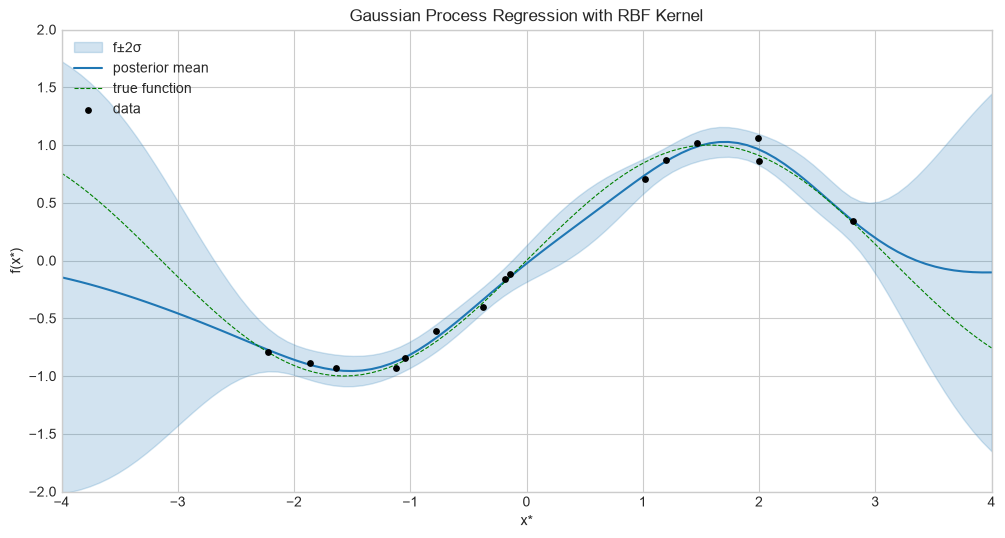

In [7]:
# training data
n = 15
X = rng.uniform(-3, 3, size=(n, 1))
noise_var = 0.1**2
y = np.sin(X[:, 0]) + rng.normal(0, np.sqrt(noise_var), size=n)

# test points
x_star = np.linspace(-4, 4, 100).reshape(-1, 1)

mean, var = GP(X, x_star, y, noise_var)
sd = np.sqrt(np.clip(var, 0, None))  # clip: rounding can give tiny negatives
xs = x_star[:, 0]  # 1-D copy for plotting

fig, ax = plt.subplots(figsize=(12, 6))
ax.fill_between(xs, mean - 2 * sd, mean + 2 * sd, color="C0", alpha=0.2, label="f±2σ")
ax.plot(xs, mean, color="C0", label="posterior mean")
ax.plot(xs, np.sin(xs), "g--", lw=0.8, label="true function")  # only if you know it
ax.scatter(X[:, 0], y, color="k", s=15, zorder=3, label="data")
ax.set_xlabel("x*")
ax.set_ylabel("f(x*)")
ax.set_title("Gaussian Process Regression with RBF Kernel")
ax.set_xlim(-4, 4)
ax.set_ylim(-2, 2)
ax.legend(loc="upper left", fontsize=10)
plt.show()

## Task 2
Optimise the lengthscale ℓ by maximising the log marginal likelihood. How does ℓ change with denser training data?